# Модель PD покупателя: обучение и проверка
Версия 1.0 · «Смарт-факторинг» · по ТЗ «Обучение модели PD покупателя» v1.1

Что делает ноутбук: берёт выборку из витрины RFSD (когорты 2022 и 2023), строит признаки по разделу 6 ТЗ, обучает бустинг и логистическую регрессию на когорте 2022, калибрует PD, задаёт уровни A–D, проверяет на когорте 2023 и показывает главные факторы по SHAP. Подбор параметров (долгий) уже выполнен скриптами `02`–`04`, его результаты лежат в `out/`; здесь параметры берутся оттуда.

**Правило:** когорта 2023 в настройке не участвует: ни признаки, ни параметры, ни калибровка, ни границы уровней.

In [1]:
import json, numpy as np, pandas as pd, lightgbm as lgb, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from pd_data import *
from pd_features import FEATURES, NUM_COLS, RU_NAMES
from pd_model import *
from pd_metrics import *
pd.set_option("display.width", 160)
a, b, fb, Xa, Xb = load()
print("когорта 2022:", len(a), " когорта 2023:", len(b))

когорта 2022: 182584  когорта 2023: 210511


## 1. Гейт 0: витрина воспроизводит наши списки ИНН

In [2]:
import os
g = json.load(open(os.path.join(ROOT, "out", "01_extract_report.json")))
pd.DataFrame({k.replace("gate0_", "когорта "): v for k, v in g.items() if k.startswith("gate0")}).T

,cohort_list,showcase_filtered,common,only_showcase,only_list
когорта 2022,182584,182584,182584,0,0
когорта 2023,210511,210511,210511,0,0


## 2. Выборка и метки
Основная метка — `y_B_12m` (банкротство или исключение из ЕГРЮЛ в окне 12 месяцев после даты среза). Строки с пустой меткой в обучение и проверку не берутся.

In [3]:
rows = []
for coh, d in (("2022 (обучение)", a), ("2023 (проверка)", b)):
    for c in ("y_B_12m", "y_A_12m", "y_0_12m", "y_B_21m"):
        if c in d.columns and d[c].notna().any():
            rows.append(dict(когорта=coh, метка=c, строк=int(d[c].notna().sum()), дефолтов=int(d[c].sum()), доля=round(float(d[c].mean()) * 100, 2)))
pd.DataFrame(rows)

,когорта,метка,строк,дефолтов,доля
0,2022 (обучение),y_B_12m,174351,2182,1.25
1,2022 (обучение),y_A_12m,169372,828,0.49
2,2022 (обучение),y_0_12m,182584,2454,1.34
3,2023 (проверка),y_B_12m,203674,2523,1.24
4,2023 (проверка),y_A_12m,199896,820,0.41
5,2023 (проверка),y_0_12m,210511,3175,1.51
6,2023 (проверка),y_B_21m,203674,5575,2.74


## 3. Признаки
Формулы и значения полей — в `out/pd_fields.md`. Коэффициенты обрезаны по 1-му и 99-му перцентилю когорты 2022, деление на ноль даёт пропуск.

In [4]:
print(len(FEATURES), "признаков:", FEATURES)
Xa[NUM_COLS].describe().T[["count", "mean", "min", "50%", "max"]].round(3)

28 признаков: ['log_revenue', 'log_assets', 'age', 'net_margin', 'debt_to_revenue', 'receivables_days', 'payables_days', 'equity_change_1y', 'interest_coverage', 'revenue_growth_1y', 'cash_ratio', 'current_ratio', 'equity_ratio', 'current_ratio_change_1y', 'revenue_growth_2y', 'equity_change_2y', 'current_ratio_change_2y', 'simplified_form', 'no_prev_report', 'receivables_faster_than_revenue', 'payables_faster_than_revenue', 'loss', 'two_years_losses', 'negative_equity', 'revenue_drop_30', 'is_moscow_mo', 'okved_section', 'region_group']


,count,mean,min,50%,max
log_revenue,182584.0,12.808,11.695,12.476,21.779
log_assets,182310.0,11.988,0.000,11.871,22.066
age,182584.0,10.109,0.000,8.000,65.000
net_margin,182571.0,0.067,-0.358,0.028,0.704
debt_to_revenue,65954.0,0.361,0.000,0.072,7.304
receivables_days,181220.0,101.783,0.160,56.797,921.720
payables_days,179491.0,162.722,0.261,70.847,2422.851
equity_change_1y,131511.0,0.063,-0.868,0.048,0.574
interest_coverage,79014.0,241.277,-259.506,8.842,9513.145
revenue_growth_1y,132339.0,0.211,-0.724,0.097,3.283


## 4. Бустинг (LightGBM): кросс-валидация на 2022

In [5]:
best = json.load(open(OUT + "lgbm_best.json")); iters = int(best["iters"])
print({k: best[k] for k in ("num_leaves", "min_child_samples", "feature_fraction", "lambda_l2", "pos_weight", "iters")})
m = a.y_B_12m.notna().values
Xt, yt = Xa[m].reset_index(drop=True), a.y_B_12m[m].astype(int).values
folds = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xt, yt))
oof_raw = np.zeros(len(yt))
for k, (tr, va) in enumerate(folds):
    mdl = fit_lgb(Xt.iloc[tr], yt[tr], best, iters); oof_raw[va] = mdl.predict(Xt.iloc[va])
    print("часть", k + 1, "Gini", round(gini(yt[va], oof_raw[va]), 4))
print("Gini вне обучающих частей:", round(gini(yt, oof_raw), 4))

{'num_leaves': 31.0, 'min_child_samples': 50.0, 'feature_fraction': 0.5, 'lambda_l2': 50.0, 'pos_weight': 5.0, 'iters': 185.0}


часть 1 Gini 0.8332


часть 2 Gini 0.7897


часть 3 Gini 0.8126


часть 4 Gini 0.8113


часть 5 Gini 0.8214
Gini вне обучающих частей: 0.8131


Результаты подбора параметров (14 вариантов, пять частей):

In [6]:
pd.read_csv(OUT + "lgbm_search.csv").round(4)

,num_leaves,min_child_samples,feature_fraction,lambda_l2,pos_weight,mean_gini,std_gini,iters,sec
0,31,50,0.5,50,5,0.8144,0.0137,185,36
1,63,300,0.7,50,5,0.8141,0.0134,150,44
2,15,600,0.5,10,20,0.8140,0.0154,254,34
3,31,300,0.5,50,5,0.8135,0.0155,197,38
4,31,300,0.5,1,5,0.8123,0.0146,143,28
5,15,100,0.9,1,20,0.8122,0.0140,216,34
6,15,100,0.9,50,1,0.8120,0.0174,436,65
7,31,100,0.8,10,1,0.8115,0.0150,237,49
8,31,100,0.9,1,1,0.8115,0.0130,207,39
9,7,600,0.5,50,5,0.8106,0.0189,499,49


## 5. Логистическая регрессия и CatBoost для сравнения
В кросс-валидации по 2022 и на проверке 2023 (таблица посчитана скриптом `05c`, на тех же частях):

In [7]:
pd.read_csv(OUT + "model_comparison.csv").round(4)

,model,cv_gini_mean,cv_gini_std,test12_gini,test21_gini,test12_ci_low,test12_ci_high,note,lgbm_minus_this_cv_mean,lgbm_better_in_folds
0,LightGBM,0.8136,0.0143,0.7607,0.7251,0.7473,0.7735,NaN,NaN,NaN
1,LogReg linear,0.7131,0.0188,0.6703,0.6512,0.6540,0.6874,NaN,0.1006,5/5
2,LogReg splines,0.7894,0.0212,0.7443,0.7087,0.7301,0.7574,NaN,0.0242,5/5
3,CatBoost,0.8068,0.0000,0.7416,0.7166,0.7266,0.7555,CV from search (early stopping per fold); fold...,NaN,NaN


Бустинг остаётся. Он лучше обычной логистической регрессии на 0,10 Gini в кросс-валидации (в каждой из пяти частей) и на 0,09 на проверке 2023. Регрессия со сплайнами (нелинейные члены) ближе: бустинг лучше неё в каждой из пяти частей, в среднем на 0,024, на проверке 2023 на 0,016. CatBoost слабее: на 0,007 в кросс-валидации и на 0,019 на проверке.

## 6. Калибровка
Обучали с весом класса 5, поэтому «сырые» скоры завышены. Калибровку строим на предсказаниях вне обучающих частей. Сравнили изотоническую и Platt на перекрёстной проверке (логлосс, Brier):

In [8]:
print(json.dumps(json.load(open(OUT + "calibration_methods.json")), indent=1))
cal = fit_calibrator(oof_raw, yt)
oof_pd = np.clip(cal.predict(oof_raw), PD_FLOOR, PD_CAP)
print("Platt: a=%.3f b=%.3f, средний PD %.4f, доля дефолтов %.4f" % (cal.a, cal.b, oof_pd.mean(), yt.mean()))

{
 "isotonic": {
  "logloss": 0.04781617025393674,
  "brier": 0.011006175229923674,
  "mean_pd": 0.012596635211789263
 },
 "platt": {
  "logloss": 0.04771536205281963,
  "brier": 0.011003615257871581,
  "mean_pd": 0.012485090343716646
 },
 "raw_uncalibrated": {
  "logloss": 0.0657030169899074,
  "brier": 0.0154256188215697,
  "mean_pd": 0.04147659181923092
 }
}


Platt: a=0.986 b=-1.517, средний PD 0.0125, доля дефолтов 0.0125


## 7. Уровни риска A–D
Границы заданы по 2022 (вне обучающих частей) так, чтобы доля дефолтов росла от A к D: A < 0,4%, B 0,4–1,5%, C 1,5–6%, D ≥ 6%.

In [9]:
cuts = [0.004, 0.015, 0.06]
level_table(yt, assign_level(oof_pd, cuts)).round(4)

,level,n,defaults,default_rate,share
0,A,109131,146,0.0013,0.6259
1,B,40942,330,0.0081,0.2348
2,C,16639,496,0.0298,0.0954
3,D,7639,1210,0.1584,0.0438


## 8. Финальная модель и проверка на когорте 2023

In [10]:
booster = fit_lgb(Xt, yt, best, int(round(iters * 1.1)))
model = PDModel(fb, booster, cal, cuts)
mb = b.y_B_12m.notna().values; m21 = b.y_B_21m.notna().values
y12, y21 = b.y_B_12m[mb].astype(int).values, b.y_B_21m[m21].astype(int).values
p12, p21 = model.predict_pd(Xb[mb]), model.predict_pd(Xb[m21])
seg = (b.loc[mb, "line_2110"] >= 800000).values
out = pd.DataFrame([
    dict(выборка="12 мес., все", n=len(y12), дефолтов=int(y12.sum()), Gini=gini(y12, p12), ci=boot_gini(y12, p12, n=300)),
    dict(выборка="12 мес., выручка от 800 млн ₽", n=int(seg.sum()), дефолтов=int(y12[seg].sum()), Gini=gini(y12[seg], p12[seg]), ci=boot_gini(y12[seg], p12[seg], n=300)),
    dict(выборка="21 мес., все", n=len(y21), дефолтов=int(y21.sum()), Gini=gini(y21, p21), ci=boot_gini(y21, p21, n=300)),
])
out["Gini"] = out["Gini"].round(3); out["ci"] = out["ci"].apply(lambda t: f"{t[0]:.3f}–{t[1]:.3f}")
out

,выборка,n,дефолтов,Gini,ci
0,"12 мес., все",203674,2523,0.761,0.747–0.773
1,"12 мес., выручка от 800 млн ₽",39924,536,0.836,0.810–0.856
2,"21 мес., все",203674,5575,0.725,0.716–0.735


**Калибровка по децилям** (когорта 2023, 12 месяцев). Средний PD против фактической доли дефолтов:

In [11]:
dt = decile_table(y12, p12); dt["разрыв, п.п."] = ((dt.mean_pd - dt.default_rate) * 100).round(2); dt.round(4)

,decile,n,mean_pd,default_rate,defaults,"разрыв, п.п."
0,1,20368,0.0005,0.0003,6,0.02
1,2,20367,0.0006,0.0007,15,-0.01
2,3,20367,0.0010,0.0011,22,-0.01
3,4,20368,0.0014,0.0018,36,-0.03
4,5,20367,0.0020,0.0029,60,-0.09
5,6,20367,0.0029,0.0046,94,-0.17
6,7,20368,0.0043,0.0062,127,-0.19
7,8,20367,0.0070,0.0092,187,-0.22
8,9,20367,0.0142,0.0149,304,-0.07
9,10,20368,0.1015,0.0821,1672,1.94


**Уровни A–D на 2023** (доля дефолтов должна расти):

In [12]:
pd.concat([level_table(y12, model.level(p12)).assign(окно="12 мес."), level_table(y21, model.level(p21)).assign(окно="21 мес.")]).round(4)

,level,n,defaults,default_rate,share,окно
0,A,128855,263,0.0020,0.6327,12 мес.
1,B,46831,449,0.0096,0.2299,12 мес.
2,C,18750,483,0.0258,0.0921,12 мес.
3,D,9238,1328,0.1438,0.0454,12 мес.
0,A,128855,720,0.0056,0.6327,21 мес.
1,B,46831,1206,0.0258,0.2299,21 мес.
2,C,18750,1249,0.0666,0.0921,21 мес.
3,D,9238,2400,0.2598,0.0454,21 мес.


**Стабильность (PSI):** скор между обучением (вне обучающих частей) и проверкой, и самые нестабильные признаки.

In [13]:
psi_s = psi(oof_pd, p12, edges=np.quantile(oof_pd, np.linspace(0, 1, 11)))
psi_f = pd.Series({c: psi(Xa[c].astype(float), Xb[c].astype(float)) for c in NUM_COLS}).sort_values(ascending=False)
print("PSI скора: %.4f (порог 0,25)" % psi_s); psi_f.head(5).round(4)

PSI скора: 0.0058 (порог 0,25)


revenue_growth_1y          0.0144
current_ratio_change_1y    0.0085
revenue_growth_2y          0.0061
age                        0.0055
equity_change_1y           0.0029
dtype: float64

## 9. Проверка на утечку
Все признаки считаются из отчётности за год T (с лагами T−1, T−2); данных после даты среза в признаках нет: поля витрины с датами ликвидации и событиями убраны из выборки на этапе `01_extract_cohorts.py`. Что проверено (результаты — в `out/pd_results.json`):
- возраст считается как год отчётности минус год регистрации; лаги T−1 и T−2 когорты 2023 совпадают со значениями когорты 2022 для 100% общих компаний;
- Gini на проверке 0,76: ниже порога подозрения 0,9; максимальный Gini одного признака 0,52;
- модель не держится на одном признаке: без маржи Gini 0,801, без маржи и абсолютной ликвидности 0,785, без возраста и признака «нет отчётности за прошлый год» 0,803;
- ранжирование сохраняется в течение окна: чем дальше от среза дефолт, тем ниже Gini (по кварталам 0,80 / 0,83 / 0,69 / 0,71).

Что проверить нельзя: дату подачи отчётности. Витрина её не хранит, поэтому не доказано, что отчётность года T была подана до даты среза. Поле витрины `pit_status` само помечено как непроверенное.

In [14]:
aud = json.load(open(OUT + "pd_results.json"))["leakage_audit"]
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in aud.items() if k.startswith("cv_gini") or k.startswith("max_")}

{'cv_gini_all_features': 0.813,
 'cv_gini_without_net_margin': 0.801,
 'cv_gini_without_net_margin_and_cash_ratio': 0.785,
 'cv_gini_without_age_and_no_prev_report': 0.803,
 'max_single_feature_abs_gini': 0.515}

## 10. SHAP: главные факторы и `score(inn)`

In [15]:
sample = np.random.default_rng(1).choice(len(Xb[mb]), 20000, replace=False)
sv = model.contributions(Xb[mb].iloc[sample])[:, :-1]
imp = pd.Series(np.abs(sv).mean(0), index=FEATURES).sort_values(ascending=False)
imp.index = [RU_NAMES.get(i, i) for i in imp.index]; imp.head(10).round(3)

маржа чистой прибыли                     0.457
возраст компании                         0.350
абсолютная ликвидность                   0.349
изменение выручки за год                 0.193
изменение выручки за два года            0.188
доля собственного капитала               0.173
дни оборота дебиторской задолженности    0.138
размер активов                           0.134
покрытие процентов                       0.133
вид деятельности (раздел ОКВЭД)          0.132
dtype: float64

In [16]:
import os
os.environ["PD_STORE_PATHS"] = os.path.join(ROOT, "data", "scoring_store_2024.parquet")
os.environ["PD_MODEL_PATH"] = os.path.join(ROOT, "out", "pd_model.pkl")
from score_inn import score, score_many
store_inns = pd.read_parquet(os.environ["PD_STORE_PATHS"], columns=["inn", "line_2110"])
demo = store_inns[store_inns.line_2110 >= 800000].inn.sample(3, random_state=5).tolist()
for i in demo:
    r = score(i); print(i, "PD=%.2f%%" % (r["pd"] * 100), "уровень", r["level"]); [print("   ", f["text"]) for f in r["factors"]]
print(score("0000000000"))

0276128576 PD=0.05% уровень A
    вид деятельности (раздел ОКВЭД): Q — снижает риск
    маржа чистой прибыли: 33.5% — снижает риск
    возраст компании: 14 г. — снижает риск
7701600369 PD=7.35% уровень D
    изменение выручки за год: -54.5% — повышает риск
    доля собственного капитала: -83.1% — повышает риск
    изменение выручки за два года: -74.8% — повышает риск
9701103804 PD=0.05% уровень A
    маржа чистой прибыли: 12.1% — снижает риск
    изменение выручки за год: 29.4% — снижает риск
    покрытие процентов: 11.27 — снижает риск
{'inn': '0000000000', 'status': 'no_financials', 'pd': None, 'level': None, 'factors': []}


## 11. Графики

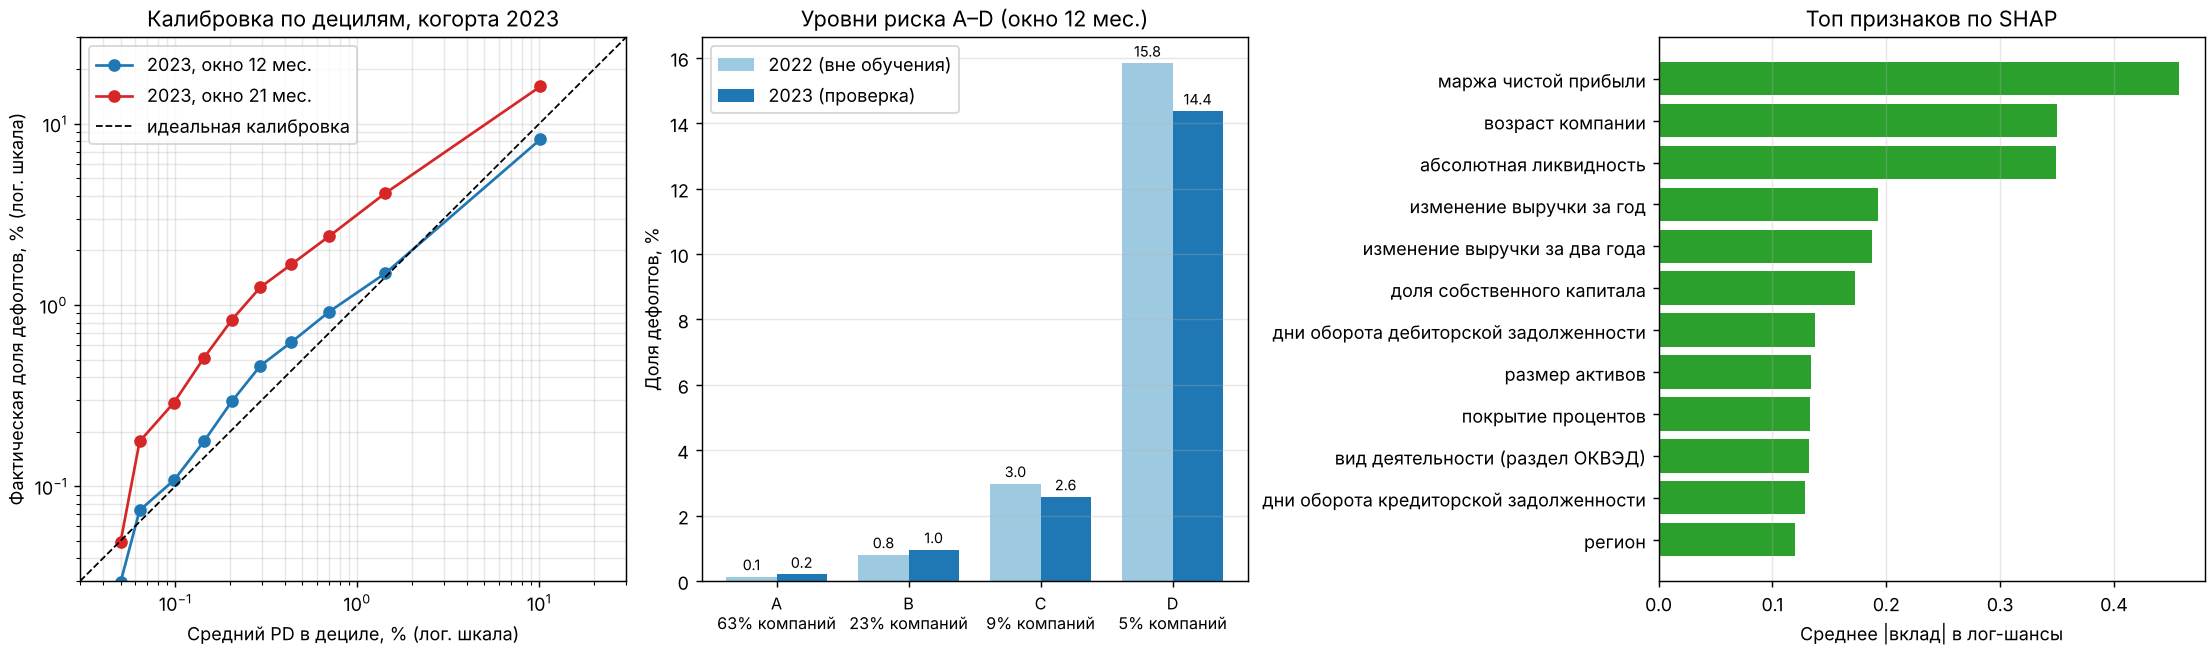

In [17]:
from IPython.display import Image
Image(OUT + "pd_report_plots.png")

## 12. Варианты метки Б, А, 0 на кросс-валидации внутри 2022
Одна и та же модель и признаки, одни и те же части; таблица из скрипта `06_label_variants.py`:

In [18]:
pd.read_csv(OUT + "label_variants_cv.csv").round(4)

,trained_on,evaluated_against,n,defaults,gini,ci_low,ci_high,fold_std
0,B,target B (bankruptcy + exclusion),174351,2182,0.8133,0.8013,0.8251,0.0185
1,B,target A (bankruptcy only),169372,828,0.7462,0.7242,0.7702,0.0237
2,A,target B (bankruptcy + exclusion),174351,2182,0.6815,0.6671,0.6967,0.0373
3,A,target A (bankruptcy only),169372,828,0.7770,0.7563,0.7974,0.0333
4,0,target B (bankruptcy + exclusion),174351,2182,0.6792,0.6600,0.6978,0.0165
5,0,target A (bankruptcy only),169372,828,0.4301,0.3965,0.4652,0.0231


Вариант Б (банкротство и исключение) лучше всего предсказывает «любой дефолт» (Gini 0,81) и теряет около 0,03 на чистых банкротствах по сравнению с моделью, обученной только на банкротствах (0,75 против 0,78). Модель, обученная только на банкротствах, на исключениях заметно слабее (0,68). Вариант 0 (любая ликвидация, включая реорганизации и добровольные) слабее по обеим целям, особенно на банкротствах (0,43). Выбор варианта Б по ТЗ подтверждается.